In [1]:
import utils
import xarray as xr
import numpy as np
import dask
from distributed import Client
from dask.distributed import wait
from ncar_jobqueue import NCARCluster
from glob import glob
import intake
import importlib
import pop_tools
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
xr.set_options(keep_attrs=True)

## Spin up DASK cluster

In [2]:
def get_ClusterClient():
    import dask
    from dask_jobqueue import PBSCluster
    from dask.distributed import Client
    cluster = PBSCluster(
        cores=2,
        memory='20 GB',
        processes=1,
        queue='casper',
        resource_spec='select=1:ncpus=1:mem=20GB',
        project='NCGD0011',
        walltime='02:00:00',
        interface='ext',)

    dask.config.set({
        'distributed.dashboard.link':
        'https://jupyterhub.hpc.ucar.edu/stable/user/{USER}/proxy/{port}/status'
    })
    client = Client(cluster)
    return cluster, client

In [3]:
cluster, client = get_ClusterClient()
cluster.scale(20) 
client

Client Scheduler: tcp://128.117.208.175:35379 Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/kristenk/proxy/8787/status,Cluster Workers: 0 Cores: 0 Memory: 0 B


### Load the Data Catalog

In [4]:
catalog = intake.open_esm_datastore(
    '/glade/collections/cmip/catalog/intake-esm-datastore/catalogs/glade-cesm2-le.json'
)

### Get the historical data

In [5]:
subset = catalog.search(component='lnd',
                        variable='NPP',
                        experiment='historical',
                        forcing_variant='cmip6',
                        stream='clm2.h0'
                       )
with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    dsets = subset.to_dataset_dict()


--> The keys in the returned dictionary of datasets are constructed as follows:
	'component.experiment.stream.forcing_variant.variable'


In [6]:
dsets.keys()

dict_keys(['lnd.historical.clm2.h0.cmip6.NPP'])

In [7]:
%%time
# load historical
ds_hist = dsets['lnd.historical.clm2.h0.cmip6.NPP']
ds_hist

CPU times: user 12 µs, sys: 1 µs, total: 13 µs
Wall time: 18.6 µs


<xarray.Dataset>
Dimensions:       (hist_interval: 2, lat: 192, levdcmp: 25, levgrnd: 25, levlak: 10, lon: 288, member_id: 50, time: 1980)
Coordinates:
  * levgrnd       (levgrnd) float32 0.01 0.04 0.09 0.16 ... 19.48 28.87 42.0
  * levlak        (levlak) float32 0.05 0.6 2.1 4.6 ... 18.6 25.6 34.33 44.78
  * levdcmp       (levdcmp) float32 0.01 0.04 0.09 0.16 ... 19.48 28.87 42.0
  * lon           (lon) float32 0.0 1.25 2.5 3.75 ... 355.0 356.2 357.5 358.8
  * lat           (lat) float32 -90.0 -89.06 -88.12 -87.17 ... 88.12 89.06 90.0
  * time          (time) object 1850-02-01 00:00:00 ... 2015-01-01 00:00:00
  * member_id     (member_id) <U12 'r10i1181p1f1' ... 'r9i1301p1f1'
Dimensions without coordinates: hist_interval
Data variables: (12/22)
    area          (lat, lon) float32 dask.array<chunksize=(192, 288), meta=np.ndarray>
    landfrac      (lat, lon) float32 dask.array<chunksize=(192, 288), meta=np.ndarray>
    landmask      (lat, lon) float64 dask.array<chunksize=(192, 288), meta=np.ndarray>
    pftmask       (lat, lon) float64 dask.array<chunksize=(192, 288), meta=np.ndarray>
    nbedrock      (lat, lon) float64 dask.array<chunksize=(192, 288), meta=np.ndarray>
    ZSOI          (levgrnd, lat, lon) float32 dask.array<chunksize=(25, 192, 288), meta=np.ndarray>
    ...            ...
    mscur         (time) float64 dask.array<chunksize=(120,), meta=np.ndarray>
    nstep         (time) float64 dask.array<chunksize=(120,), meta=np.ndarray>
    time_bounds   (time, hist_interval) object dask.array<chunksize=(120, 2), meta=np.ndarray>
    date_written  (time) object dask.array<chunksize=(120,), meta=np.ndarray>
    time_written  (time) object dask.array<chunksize=(120,), meta=np.ndarray>
    NPP           (member_id, time, lat, lon) float32 dask.array<chunksize=(1, 120, 192, 288), meta=np.ndarray>
Attributes: (12/103)
    ctype_urban_shadewall:                     73
    cft_cassava:                               19
    ctype_urban_sunwall:                       72
    cft_irrigated_miscanthus:                  58
    cft_irrigated_cassava:                     20
    cft_irrigated_temperate_corn:              4
    ...                                        ...
    cft_barley:                                11
    cft_irrigated_pulses:                      44
    cft_irrigated_sorghum:                     50
    cft_switchgrass:                           59
    cft_spring_wheat:                          5
    intake_esm_dataset_key:                    lnd.historical.clm2.h0.cmip6.NPP

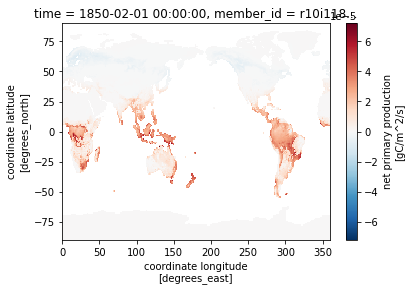

In [8]:
ds_hist.NPP.isel(member_id=0,time=0).plot()

### Load future data

In [9]:
%%time
subset = catalog.search(component='lnd',
                        variable='NPP',
                        experiment='ssp370',
                        forcing_variant='cmip6',
                        stream='clm2.h0'
                       )
with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    dsets = subset.to_dataset_dict()


--> The keys in the returned dictionary of datasets are constructed as follows:
	'component.experiment.stream.forcing_variant.variable'


CPU times: user 7.56 s, sys: 316 ms, total: 7.87 s
Wall time: 9.48 s


In [10]:
dsets.keys()

dict_keys(['lnd.ssp370.clm2.h0.cmip6.NPP'])

In [11]:
ds_ssp = dsets['lnd.ssp370.clm2.h0.cmip6.NPP']

## Concatenate historical and future datasets, keep just years of interest

In [12]:
ds = xr.concat((ds_hist, ds_ssp),dim='time')
ds.time

<xarray.DataArray 'time' (time: 3012)>
array([cftime.DatetimeNoLeap(1850, 2, 1, 0, 0, 0, 0),
       cftime.DatetimeNoLeap(1850, 3, 1, 0, 0, 0, 0),
       cftime.DatetimeNoLeap(1850, 4, 1, 0, 0, 0, 0), ...,
       cftime.DatetimeNoLeap(2100, 11, 1, 0, 0, 0, 0),
       cftime.DatetimeNoLeap(2100, 12, 1, 0, 0, 0, 0),
       cftime.DatetimeNoLeap(2101, 1, 1, 0, 0, 0, 0)], dtype=object)
Coordinates:
  * time     (time) object 1850-02-01 00:00:00 ... 2101-01-01 00:00:00
Attributes:
    long_name:  time
    bounds:     time_bounds

In [13]:
ds['time'] = ds.time_bounds.compute().mean(dim="hist_interval")

In [15]:
keepthese=['lat','lon','member_id','time','NPP','area']
ds = ds.drop([v for v in ds.variables if v not in keepthese])

In [16]:
ds

<xarray.Dataset>
Dimensions:    (lat: 192, lon: 288, member_id: 50, time: 3012)
Coordinates:
  * lon        (lon) float32 0.0 1.25 2.5 3.75 5.0 ... 355.0 356.2 357.5 358.8
  * lat        (lat) float32 -90.0 -89.06 -88.12 -87.17 ... 88.12 89.06 90.0
  * time       (time) object 1850-01-16 11:45:00 ... 2100-12-16 12:00:00
  * member_id  (member_id) <U12 'r10i1181p1f1' 'r10i1231p1f1' ... 'r9i1301p1f1'
Data variables:
    area       (time, lat, lon) float32 dask.array<chunksize=(1980, 192, 288), meta=np.ndarray>
    NPP        (member_id, time, lat, lon) float32 dask.array<chunksize=(1, 120, 192, 288), meta=np.ndarray>
Attributes: (12/103)
    ctype_urban_shadewall:                     73
    cft_cassava:                               19
    ctype_urban_sunwall:                       72
    cft_irrigated_miscanthus:                  58
    cft_irrigated_cassava:                     20
    cft_irrigated_temperate_corn:              4
    ...                                        ...
    cft_barley:                                11
    cft_irrigated_pulses:                      44
    cft_irrigated_sorghum:                     50
    cft_switchgrass:                           59
    cft_spring_wheat:                          5
    intake_esm_dataset_key:                    lnd.historical.clm2.h0.cmip6.NPP

### Compute annual means and write out the data

In [17]:
%%time
######## make annual mean

ds_ann = ds.resample({'time':'A'}).mean(dim='time').compute()

CPU times: user 17.6 s, sys: 2.74 s, total: 20.4 s
Wall time: 25.7 s


In [18]:
ds_ann

<xarray.Dataset>
Dimensions:    (lat: 192, lon: 288, member_id: 50, time: 251)
Coordinates:
  * time       (time) object 1850-12-31 00:00:00 ... 2100-12-31 00:00:00
  * lon        (lon) float32 0.0 1.25 2.5 3.75 5.0 ... 355.0 356.2 357.5 358.8
  * lat        (lat) float32 -90.0 -89.06 -88.12 -87.17 ... 88.12 89.06 90.0
  * member_id  (member_id) <U12 'r10i1181p1f1' 'r10i1231p1f1' ... 'r9i1301p1f1'
Data variables:
    area       (time, lat, lon) float32 29.95 29.95 29.95 29.95 ... nan nan nan
    NPP        (time, member_id, lat, lon) float32 0.0 0.0 0.0 ... nan nan nan
Attributes: (12/103)
    ctype_urban_shadewall:                     73
    cft_cassava:                               19
    ctype_urban_sunwall:                       72
    cft_irrigated_miscanthus:                  58
    cft_irrigated_cassava:                     20
    cft_irrigated_temperate_corn:              4
    ...                                        ...
    cft_barley:                                11
    cft_irrigated_pulses:                      44
    cft_irrigated_sorghum:                     50
    cft_switchgrass:                           59
    cft_spring_wheat:                          5
    intake_esm_dataset_key:                    lnd.historical.clm2.h0.cmip6.NPP

In [19]:
# Export the dataset to NetCDF with all attributes and coordinates
#ds_ann.to_netcdf('/glade/derecho/scratch/kristenk/ToE_saved_data/NPPland_annual_means_1850-2100.nc', mode='w')

## ToE ANALYSIS

In [20]:
ds_ann

<xarray.Dataset>
Dimensions:    (lat: 192, lon: 288, member_id: 50, time: 251)
Coordinates:
  * time       (time) object 1850-12-31 00:00:00 ... 2100-12-31 00:00:00
  * lon        (lon) float32 0.0 1.25 2.5 3.75 5.0 ... 355.0 356.2 357.5 358.8
  * lat        (lat) float32 -90.0 -89.06 -88.12 -87.17 ... 88.12 89.06 90.0
  * member_id  (member_id) <U12 'r10i1181p1f1' 'r10i1231p1f1' ... 'r9i1301p1f1'
Data variables:
    area       (time, lat, lon) float32 29.95 29.95 29.95 29.95 ... nan nan nan
    NPP        (time, member_id, lat, lon) float32 0.0 0.0 0.0 ... nan nan nan
Attributes: (12/103)
    ctype_urban_shadewall:                     73
    cft_cassava:                               19
    ctype_urban_sunwall:                       72
    cft_irrigated_miscanthus:                  58
    cft_irrigated_cassava:                     20
    cft_irrigated_temperate_corn:              4
    ...                                        ...
    cft_barley:                                11
    cft_irrigated_pulses:                      44
    cft_irrigated_sorghum:                     50
    cft_switchgrass:                           59
    cft_spring_wheat:                          5
    intake_esm_dataset_key:                    lnd.historical.clm2.h0.cmip6.NPP

In [21]:
ds_ann['time'] = np.arange(1850,2101,1)

In [22]:
time3d = np.full([251,192,288],1,dtype=int)

ylen = 192
xlen = 288

for x in np.arange(0,xlen,1):
    for y in np.arange(0,ylen,1):

        time3d[:,y,x]=ds_ann.time.values

time3d = xr.DataArray(time3d,dims=('time','lat','lon'))

In [23]:
%%time

#HISTORICAL PERIOD = 1850 - 1899 (50 years)

upthres_ds = xr.Dataset()
lothres_ds = xr.Dataset()

variables=['NPP']

for var in variables:
    
    ### calculate                                                                                                                                                                                                                                                                 
    mean_var = ds_ann[var].isel(time=slice(0,50)).mean(dim=('time','member_id'))
    std_var = ds_ann[var].isel(time=slice(0,50)).std(dim=('time','member_id'))
    
    var_array_upthres = mean_var + 2 * std_var
    var_array_lothres = mean_var - 2 * std_var

    upthres_ds[var] = var_array_upthres
    lothres_ds[var] = var_array_lothres

CPU times: user 580 ms, sys: 131 ms, total: 711 ms
Wall time: 693 ms


In [24]:
ToE_up = time3d.where(ds_ann.NPP.mean(dim='member_id') > upthres_ds['NPP'])
ToE_up = ToE_up.min(dim='time')

In [25]:
ToE_down = time3d.where(ds_ann.NPP.mean(dim='member_id') < lothres_ds['NPP'])
ToE_down = ToE_down.min(dim='time')

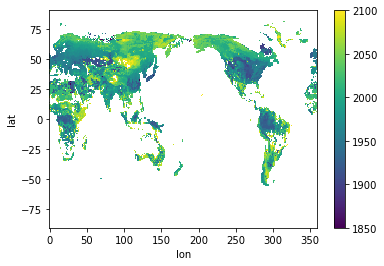

In [26]:
ToE_up.plot()

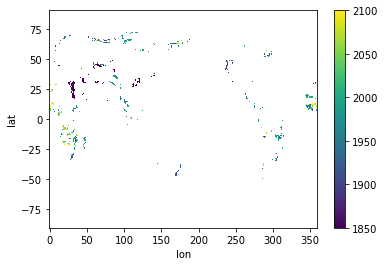

In [27]:
ToE_down.plot()

### Make a map of the ToE times

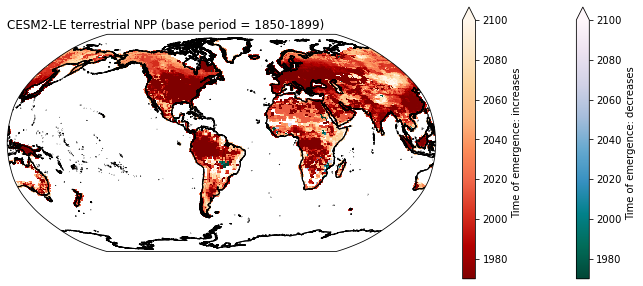

In [29]:
fig = plt.figure(figsize=(12,5))

############### 
ax = fig.add_subplot(1,1,1, projection=ccrs.Robinson(central_longitude=305.0))
#ax.set_extent([-180, 180, -90, -30], ccrs.PlateCarree())
ax.set_title('CESM2-LE terrestrial NPP (base period = 1850-1899)', loc='left')

pc = ax.pcolormesh(ds_ann.lon,ds_ann.lat,ToE_down,
                    transform=ccrs.PlateCarree(),cmap='PuBuGn_r',
                   vmin=1970,vmax=2100)


ax.coastlines('10m',linewidth=1)
fig.colorbar(pc,extend='max', label='Time of emergence: decreases');

pc = ax.pcolormesh(ds_ann.lon,ds_ann.lat,ToE_up,
                    transform=ccrs.PlateCarree(),cmap='OrRd_r',
                   vmin=1970,vmax=2100)


ax.coastlines('10m',linewidth=1)
fig.colorbar(pc,extend='max', label='Time of emergence: increases');

#fig.savefig('/glade/work/kristenk/figs/CESM2-LE-ToE-AirTemp2m.png', bbox_inches='tight', dpi=300, format='png');

In [32]:
area = ds_ann.area.isel(time=0).squeeze()

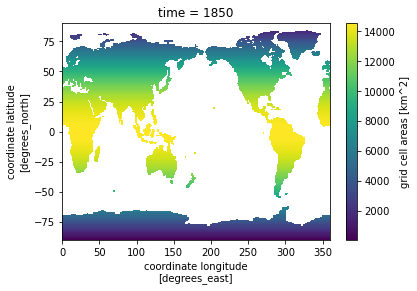

In [34]:
area.plot()

In [37]:
area_m2 = area * 1e6

### Make plot of global 2m air temp (area-weighted)

In [38]:
glb_terrNPP = (ds_ann.NPP * 86400 * 365 * area_m2).sum(dim=('lon','lat'))

In [40]:
glb_terrNPP = glb_terrNPP.load() * 1e-15

In [45]:

#SIZ
mean = glb_terrNPP.isel(time=slice(0,50)).mean(dim=('time','member_id')).values
std = glb_terrNPP.isel(time=slice(0,50)).std(dim=('time','member_id')).values
toe_npp = glb_terrNPP.time.where(glb_terrNPP.mean(dim='member_id') > mean+2*std).min(dim='time')
toe_npp_val = mean+2*std
print(toe_npp, toe_npp_val)

<xarray.DataArray 'time' ()>
array(1936.) 47.750210674557636


Text(0.5, 0, 'Year')

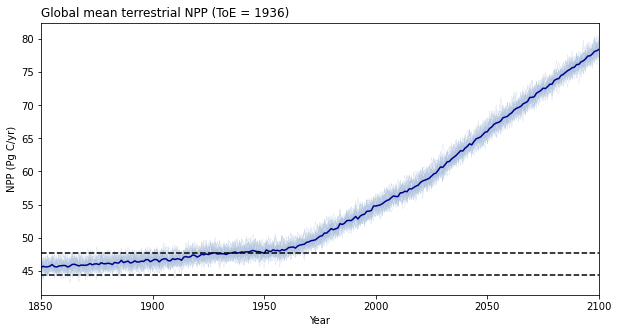

In [46]:
fig = plt.figure(figsize=(10,5))

#################
ax = fig.add_subplot(1, 1, 1)
ax.set_title("Global mean terrestrial NPP (ToE = 1936)", loc="left", fontsize=12)

for mem in np.arange(0,50,1):

    ax.plot(glb_terrNPP.time, glb_terrNPP.isel(member_id=mem), color='lightsteelblue',linewidth=0.2)
    
ax.plot(glb_terrNPP.time, glb_terrNPP.mean(dim='member_id'),
           color='darkblue', zorder=2)
std_up = (glb_terrNPP.mean(dim='member_id').isel(time=slice(0,50)).mean(dim='time') + 2*glb_terrNPP.std(dim='member_id').isel(time=slice(0,50)).mean(dim='time'))
std_down = (glb_terrNPP.mean(dim='member_id').isel(time=slice(0,50)).mean(dim='time') - 2*glb_terrNPP.std(dim='member_id').isel(time=slice(0,50)).mean(dim='time'))
ax.axhline(std_up, linestyle='--',color='black')
ax.axhline(std_down, linestyle='--',color='black')
ax.set_xlim(1850,2100)
#ax.set_ylim(13,20)
ax.set_ylabel('NPP (Pg C/yr)')
ax.set_xlabel('Year')

### Get data ready for writing out

In [47]:
ds_out = xr.Dataset()

ds_out['terrestrial_NPP_ens_mean'] = ds_ann['NPP'].mean(dim='member_id') * 86400 * 365 #gC/m2/y
ds_out['terrestrial_NPP_ens_mean'].attrs = ds_ann.NPP.attrs
ds_out['terrestrial_NPP_ens_mean'].attrs['units'] = 'gC/m2/y'
ds_out['terrestrial_NPP_ens_mean'].attrs['notes'] = 'ensemble mean of 50 cmip6 forcing ensemble members'

ds_out['terrestrial_NPP_st_dev'] = ds_ann['NPP'].std(dim='member_id') * 86400 * 365 #gC/m2/y
ds_out['terrestrial_NPP_st_dev'].attrs = ds_ann.NPP.attrs
ds_out['terrestrial_NPP_st_dev'].attrs['units'] = 'gC/m2/y'
ds_out['terrestrial_NPP_st_dev'].attrs['notes'] = 'ensemble standard deviation of 50 cmip6 forcing ensemble members'

ds_out.attrs['author'] = 'Kristen Krumhardt'
ds_out.attrs['date_processed'] = datetime.now().strftime('%Y-%m-%d')
ds_out.attrs['contents'] = f'Terrestrial NPP from CESM2-LE'

ds_out

<xarray.Dataset>
Dimensions:                   (lat: 192, lon: 288, time: 251)
Coordinates:
  * time                      (time) int64 1850 1851 1852 ... 2098 2099 2100
  * lon                       (lon) float32 0.0 1.25 2.5 ... 356.2 357.5 358.8
  * lat                       (lat) float32 -90.0 -89.06 -88.12 ... 89.06 90.0
Data variables:
    terrestrial_NPP_ens_mean  (time, lat, lon) float64 0.0 0.0 0.0 ... nan nan
    terrestrial_NPP_st_dev    (time, lat, lon) float64 0.0 0.0 0.0 ... nan nan
Attributes:
    author:          Kristen Krumhardt
    date_processed:  2026-10-27
    contents:        Terrestrial NPP from CESM2-LE

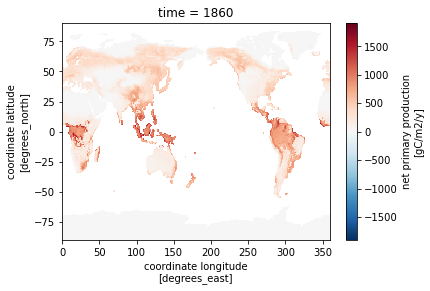

In [48]:
ds_out['terrestrial_NPP_ens_mean'].isel(time=10).plot()

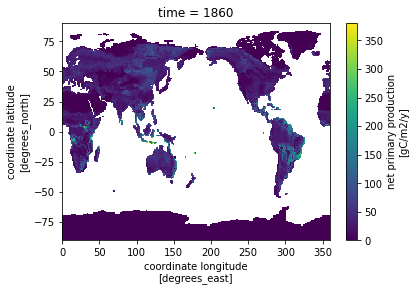

In [49]:
ds_out['terrestrial_NPP_st_dev'].isel(time=10).plot()

In [50]:
# calculate the size of the dataset in GB
size_gb = ds_out.nbytes / (1024**3)
print(f"The dataset is approximately {size_gb:.2f} GB.")

The dataset is approximately 0.21 GB.


In [51]:
path_out = '/glade/derecho/scratch/kristenk/ToE_saved_data/'
file_out = 'CESM2-LE-terrestrialNPP_ens_mean_std.nc'
fout = path_out + file_out

In [52]:
# Export the dataset to NetCDF with all attributes and coordinates
ds_out.to_netcdf(fout)

In [53]:
fout

'/glade/derecho/scratch/kristenk/ToE_saved_data/CESM2-LE-terrestrialNPP_ens_mean_std.nc'